In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os

folder_path = "/content/drive/MyDrive/Cyclistic_Project/Cyclistic_Data"

files = os.listdir(folder_path)

print("Number of files:", len(files))
print(files)

Number of files: 13
['202510-divvy-tripdata.csv', '202511-divvy-tripdata.csv', '202512-divvy-tripdata.csv', '202501-divvy-tripdata.csv', '202602-divvy-tripdata.csv', '202603-divvy-tripdata.csv', '202604-divvy-tripdata.csv', '202605-divvy-tripdata.csv', '202606-divvy-tripdata.csv', '202607-divvy-tripdata.csv', '202608-divvy-tripdata.csv', '202609-divvy-tripdata.csv', '202610-divvy-tripdata.csv']


In [10]:
import pandas as pd

jan_file = "/content/drive/MyDrive/Cyclistic_Project/Cyclistic_Data/202501-divvy-tripdata.csv"

jan = pd.read_csv(jan_file, usecols=["started_at"])

print(jan["started_at"].min())
print(jan["started_at"].max())

2025-12-31 10:30:49.482
2026-01-31 23:56:54.069


In [11]:
%pip install duckdb

In [12]:
import duckdb

print("DuckDB version:", duckdb.__version__)

DuckDB version: 1.3.2


In [13]:
import duckdb

con = duckdb.connect()

jan_path = "/content/drive/MyDrive/Cyclistic_Project/Cyclistic_Data/202601-divvy-tripdata.csv"

jan_data = con.execute(f"""
    SELECT *
    FROM read_csv_auto('{jan_path}')
    LIMIT 5
""").df()

jan_data

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,FD0EB1D32AF0D47E,classic_bike,2026-01-31 09:13:09.018,2026-01-31 09:28:10.302,Central St & Girard Ave,CHI02042,Dodge Ave & Church St,CHI00741,42.064313,-87.686152,42.048308,-87.698224,member
1,FB27405C3F8C824F,classic_bike,2026-01-15 14:25:42.526,2026-01-15 14:33:18.854,Shore Dr & 55th St,CHI00394,Woodlawn Ave & 55th St,CHI00423,41.795212,-87.580715,41.795264,-87.596471,casual
2,6FAFA1709403AA27,electric_bike,2026-01-06 12:55:33.572,2026-01-06 13:02:17.922,Hampden Ct & Diversey Pkwy,CHI02087,None,None,41.932470,-87.642420,41.940000,-87.640000,member
3,1F34C1FAD9FEC2D8,electric_bike,2026-01-26 16:22:25.011,2026-01-26 16:53:15.197,Carpenter St & Huron St,CHI00286,None,None,41.894532,-87.653412,41.830000,-87.670000,member
4,8E3E3072D8D3D918,electric_bike,2026-01-10 18:13:30.139,2026-01-10 19:31:56.971,Clinton St & Madison St,CHI00233,None,None,41.881660,-87.641150,41.890000,-87.630000,member


In [14]:
DESCRIBE
SELECT *
FROM read_csv_auto(
    '/content/drive/MyDrive/Cyclistic_Project/Cyclistic_Data/202601-divvy-tripdata.csv'
);

SyntaxError: invalid syntax (2522689652.py, line 2)

In [15]:
result = con.execute("""
    DESCRIBE
    SELECT *
    FROM read_csv_auto(
        '/content/drive/MyDrive/Cyclistic_Project/Cyclistic_Data/202601-divvy-tripdata.csv'
    )
""").df()

result

,column_name,column_type,null,key,default,extra
0,ride_id,VARCHAR,YES,None,None,None
1,rideable_type,VARCHAR,YES,None,None,None
2,started_at,TIMESTAMP,YES,None,None,None
3,ended_at,TIMESTAMP,YES,None,None,None
4,start_station_name,VARCHAR,YES,None,None,None
5,start_station_id,VARCHAR,YES,None,None,None
6,end_station_name,VARCHAR,YES,None,None,None
7,end_station_id,VARCHAR,YES,None,None,None
8,start_lat,DOUBLE,YES,None,None,None
9,start_lng,DOUBLE,YES,None,None,None


In [16]:
result[['column_name', 'column_type', 'null']]

,column_name,column_type,null
0,ride_id,VARCHAR,YES
1,rideable_type,VARCHAR,YES
2,started_at,TIMESTAMP,YES
3,ended_at,TIMESTAMP,YES
4,start_station_name,VARCHAR,YES
5,start_station_id,VARCHAR,YES
6,end_station_name,VARCHAR,YES
7,end_station_id,VARCHAR,YES
8,start_lat,DOUBLE,YES
9,start_lng,DOUBLE,YES


In [17]:
import duckdb

db_path = "/content/drive/MyDrive/Cyclistic_Project/cyclistic.duckdb"

con = duckdb.connect(db_path)

folder_path = "/content/drive/MyDrive/Cyclistic_Project/Cyclistic_Data/*.csv"

con.execute(f"""
    CREATE OR REPLACE TABLE all_trips AS
    SELECT *
    FROM read_csv_auto(
        '{folder_path}',
        union_by_name = true
    )
""")

print("Combined dataset created successfully!")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Combined dataset created successfully!


In [18]:
con.execute("""
    SELECT COUNT(*) AS total_records
    FROM all_trips
""").df()

,total_records
0,6171785


In [19]:
con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT ride_id) AS unique_rides,
        COUNT(*) - COUNT(DISTINCT ride_id) AS duplicate_rides,
        COUNT(*) FILTER (WHERE ride_id IS NULL) AS missing_ride_ids,
        COUNT(*) FILTER (WHERE started_at IS NULL) AS missing_start_times,
        COUNT(*) FILTER (WHERE ended_at IS NULL) AS missing_end_times
    FROM all_trips
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,unique_rides,duplicate_rides,missing_ride_ids,missing_start_times,missing_end_times
0,6171785,6171750,35,0,0,0


In [20]:
con.execute("""
    SELECT
        ride_id,
        COUNT(*) AS occurrences
    FROM all_trips
    GROUP BY ride_id
    HAVING COUNT(*) > 1
    ORDER BY occurrences DESC
""").df()

,ride_id,occurrences
0,5232F2CB3D297D55,2
1,82EDB771CE5282E8,2
2,C9050956F58561AD,2
3,B046AA82A096C6FA,2
4,78D590AAA74CAE97,2
5,796A83D45529C7D8,2
6,03C5375398BE0649,2
7,1DB04E901469FB2F,2
8,67C08EEA3F45893E,2
9,69451215A387162E,2


In [21]:
con.execute("""
    SELECT COUNT(*) AS duplicate_groups
    FROM (
        SELECT ride_id
        FROM all_trips
        GROUP BY ride_id
        HAVING COUNT(*) > 1
    ) duplicates
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,duplicate_groups
0,35


In [22]:
con.execute("""
    SELECT *
    FROM all_trips
    WHERE ride_id IN (
        SELECT ride_id
        FROM all_trips
        GROUP BY ride_id
        HAVING COUNT(*) > 1
    )
    ORDER BY ride_id
    LIMIT 20
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,03C5375398BE0649,electric_bike,2026-04-30 23:46:36.039,2026-05-01 00:04:48.512,None,None,Clark St & Arlington Pl,CHI02109,41.900000,-87.630000,41.926940,-87.641480,member
1,03C5375398BE0649,electric_bike,2026-04-30 23:46:36.039,2026-05-01 00:04:48.512,None,None,Clark St & Arlington Pl,CHI02109,41.900000,-87.630000,41.926940,-87.641480,member
2,0612B2A21BA5E988,classic_bike,2026-04-30 15:56:11.305,2026-05-01 16:56:08.148,Fulton Market,CHI01880,None,None,41.886871,-87.648089,NaN,NaN,member
3,0612B2A21BA5E988,classic_bike,2026-04-30 15:56:11.305,2026-05-01 16:56:08.148,Fulton Market,CHI01880,None,None,41.886871,-87.648089,NaN,NaN,member
4,10117825A92C182D,classic_bike,2026-04-30 23:56:24.321,2026-05-01 00:01:51.860,Peoria St & Kinzie St,CHI02098,Ogden Ave & Chicago Ave,CHI00275,41.888960,-87.649730,41.896362,-87.654061,casual
5,10117825A92C182D,classic_bike,2026-04-30 23:56:24.321,2026-05-01 00:01:51.860,Peoria St & Kinzie St,CHI02098,Ogden Ave & Chicago Ave,CHI00275,41.888960,-87.649730,41.896362,-87.654061,casual
6,15521787039F37E5,classic_bike,2026-04-30 23:54:44.934,2026-05-01 00:05:45.575,Michigan Ave & 11th St,CHI02025,DuSable Lake Shore Dr & Monroe St,CHI00374,41.869590,-87.623961,41.880958,-87.616743,member
7,15521787039F37E5,classic_bike,2026-04-30 23:54:44.934,2026-05-01 00:05:45.575,Michigan Ave & 11th St,CHI02025,DuSable Lake Shore Dr & Monroe St,CHI00374,41.869590,-87.623961,41.880958,-87.616743,member
8,1DB04E901469FB2F,electric_bike,2026-04-30 23:54:09.726,2026-05-01 00:11:09.709,Ravenswood Ave & Irving Park Rd,CHI00309,None,None,41.954690,-87.673930,41.970000,-87.670000,casual
9,1DB04E901469FB2F,electric_bike,2026-04-30 23:54:09.726,2026-05-01 00:11:09.709,Ravenswood Ave & Irving Park Rd,CHI00309,None,None,41.954690,-87.673930,41.970000,-87.670000,casual


In [23]:
con.execute("""
    SELECT
        COUNT(*) AS duplicate_groups,
        SUM(occurrences - 1) AS extra_records,
        COUNT(*) FILTER (
            WHERE distinct_versions = 1
        ) AS exact_duplicate_groups,
        COUNT(*) FILTER (
            WHERE distinct_versions > 1
        ) AS conflicting_groups
    FROM (
        SELECT
            ride_id,
            COUNT(*) AS occurrences,
            COUNT(DISTINCT (
                rideable_type,
                started_at,
                ended_at,
                start_station_name,
                start_station_id,
                end_station_name,
                end_station_id,
                start_lat,
                start_lng,
                end_lat,
                end_lng,
                member_casual
            )) AS distinct_versions
        FROM all_trips
        WHERE ride_id IN (
            SELECT ride_id
            FROM all_trips
            GROUP BY ride_id
            HAVING COUNT(*) > 1
        )
        GROUP BY ride_id
    ) d
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,duplicate_groups,extra_records,exact_duplicate_groups,conflicting_groups
0,35,35.0,35,0


In [24]:
con.execute("""
    CREATE OR REPLACE TABLE clean_trips AS
    SELECT *
    FROM all_trips
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY ride_id
        ORDER BY started_at
    ) = 1
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [25]:
con.execute("""
    SELECT
        COUNT(*) AS total_records,
        COUNT(DISTINCT ride_id) AS unique_rides
    FROM clean_trips
""").df()

,total_records,unique_rides
0,6171750,6171750


In [26]:
con.execute("""
    SELECT
        COUNT(*) FILTER (WHERE rideable_type IS NULL) AS missing_rideable_type,
        COUNT(*) FILTER (WHERE start_station_name IS NULL) AS missing_start_station,
        COUNT(*) FILTER (WHERE end_station_name IS NULL) AS missing_end_station,
        COUNT(*) FILTER (WHERE start_lat IS NULL) AS missing_start_lat,
        COUNT(*) FILTER (WHERE start_lng IS NULL) AS missing_start_lng,
        COUNT(*) FILTER (WHERE end_lat IS NULL) AS missing_end_lat,
        COUNT(*) FILTER (WHERE end_lng IS NULL) AS missing_end_lng,
        COUNT(*) FILTER (WHERE member_casual IS NULL) AS missing_member_casual
    FROM clean_trips
""").df()

,missing_rideable_type,missing_start_station,missing_end_station,missing_start_lat,missing_start_lng,missing_end_lat,missing_end_lng,missing_member_casual
0,0,1289480,1355473,0,0,5445,5445,0


In [27]:
con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE ended_at <= started_at
        ) AS invalid_duration,

        COUNT(*) FILTER (
            WHERE date_diff('second', started_at, ended_at) > 86400
        ) AS rides_over_24_hours,

        ROUND(
            MIN(date_diff('second', started_at, ended_at)) / 60.0, 2
        ) AS minimum_minutes,

        ROUND(
            MAX(date_diff('second', started_at, ended_at)) / 60.0, 2
        ) AS maximum_minutes

    FROM clean_trips
""").df()

,invalid_duration,rides_over_24_hours,minimum_minutes,maximum_minutes
0,29,5317,-54.78,1559.95


In [28]:
con.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE ended_at <= started_at
        ) AS invalid_trips,

        COUNT(*) FILTER (
            WHERE date_diff('second', started_at, ended_at) > 86400
        ) AS trips_over_24_hours,

        ROUND(
            MIN(epoch(ended_at - started_at)) / 60, 2
        ) AS shortest_minutes,

        ROUND(
            MAX(epoch(ended_at - started_at)) / 60, 2
        ) AS longest_minutes

    FROM clean_trips
""").df()

,invalid_trips,trips_over_24_hours,shortest_minutes,longest_minutes
0,29,5317,-54.79,1559.95


In [29]:
con.execute("""
    SELECT
        COUNT(*) AS total_clean_trips,
        ROUND(AVG(epoch(ended_at - started_at)) / 60, 2) AS average_duration_minutes,
        ROUND(MEDIAN(epoch(ended_at - started_at)) / 60, 2) AS median_duration_minutes,
        ROUND(MIN(epoch(ended_at - started_at)) / 60, 2) AS min_duration_minutes,
        ROUND(MAX(epoch(ended_at - started_at)) / 60, 2) AS max_duration_minutes
    FROM clean_trips
    WHERE ended_at > started_at
      AND date_diff('second', started_at, ended_at) <= 86400
""").df()

,total_clean_trips,average_duration_minutes,median_duration_minutes,min_duration_minutes,max_duration_minutes
0,6166404,13.92,9.2,0.0,1439.98


In [30]:
con.execute("""
    CREATE OR REPLACE TABLE analysis_trips AS
    SELECT *
    FROM clean_trips
    WHERE ended_at > started_at
      AND ended_at - started_at <= INTERVAL '24 hours'
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [31]:
con.execute("""
    SELECT
        COUNT(*) AS final_records,
        COUNT(DISTINCT ride_id) AS unique_rides
    FROM analysis_trips
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,final_records,unique_rides
0,6166404,6166404


In [32]:
con.execute("""
    SELECT
        member_casual,
        COUNT(*) AS total_rides
    FROM analysis_trips
    GROUP BY member_casual
    ORDER BY total_rides DESC
""").df()

,member_casual,total_rides
0,member,3981607
1,casual,2184797


In [33]:
monthly_trends = con.execute("""
    SELECT
        DATE_TRUNC('month', started_at) AS ride_month,
        member_casual,
        COUNT(*) AS total_rides
    FROM analysis_trips
    GROUP BY
        DATE_TRUNC('month', started_at),
        member_casual
    ORDER BY ride_month, member_casual
""").df()

monthly_trends

,ride_month,member_casual,total_rides
0,2025-09-01,casual,25
1,2025-09-01,member,33
2,2025-10-01,casual,223569
3,2025-10-01,member,421921
4,2025-11-01,casual,98871
5,2025-11-01,member,257292
6,2025-12-01,casual,28005
7,2025-12-01,member,112415
8,2026-01-01,casual,24656
9,2026-01-01,member,112933


In [34]:
monthly_trends = con.execute("""
    SELECT
        DATE_TRUNC('month', started_at) AS ride_month,
        member_casual,
        COUNT(*) AS total_rides
    FROM analysis_trips
    WHERE started_at >= TIMESTAMP '2025-10-01'
      AND started_at < TIMESTAMP '2026-10-01'
    GROUP BY
        DATE_TRUNC('month', started_at),
        member_casual
    ORDER BY ride_month, member_casual
""").df()

monthly_trends

,ride_month,member_casual,total_rides
0,2025-10-01,casual,223569
1,2025-10-01,member,421921
2,2025-11-01,casual,98871
3,2025-11-01,member,257292
4,2025-12-01,casual,28005
5,2025-12-01,member,112415
6,2026-01-01,casual,24656
7,2026-01-01,member,112933
8,2026-02-01,casual,41088
9,2026-02-01,member,160251


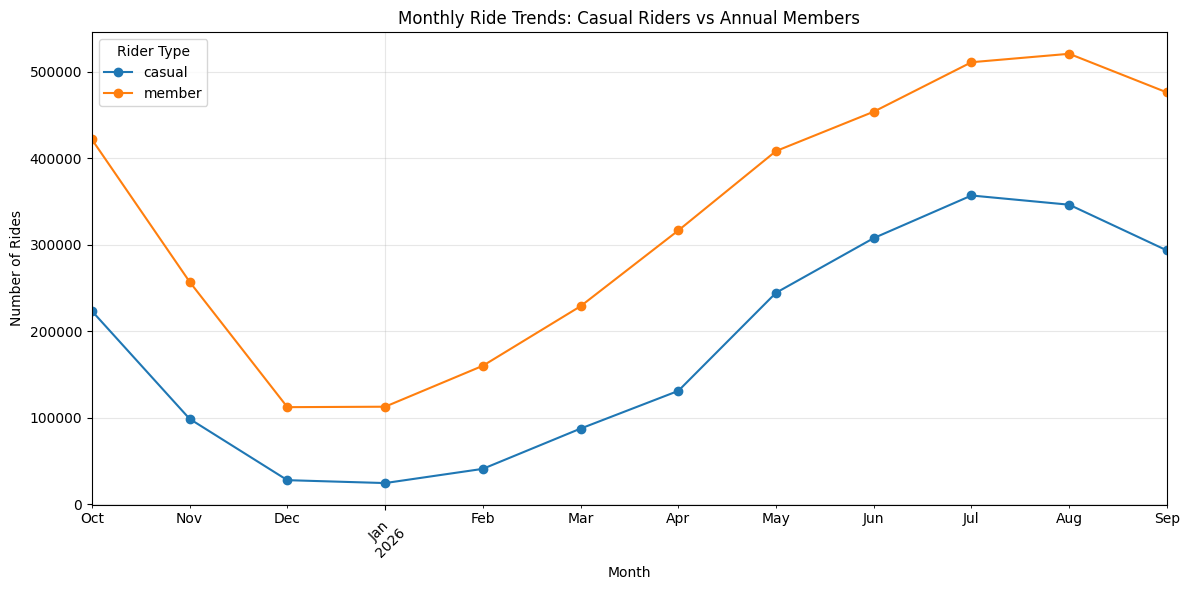

In [35]:
import matplotlib.pyplot as plt

monthly_pivot = monthly_trends.pivot(
    index='ride_month',
    columns='member_casual',
    values='total_rides'
)

monthly_pivot.plot(
    kind='line',
    figsize=(12, 6),
    marker='o'
)

plt.title('Monthly Ride Trends: Casual Riders vs Annual Members')
plt.xlabel('Month')
plt.ylabel('Number of Rides')
plt.xticks(rotation=45)
plt.legend(title='Rider Type')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
duration_comparison = con.execute("""
    SELECT
        member_casual,
        COUNT(*) AS total_rides,
        ROUND(
            AVG(date_diff('second', started_at, ended_at) / 60.0),
            2
        ) AS avg_duration_minutes,
        ROUND(
            MEDIAN(date_diff('second', started_at, ended_at) / 60.0),
            2
        ) AS median_duration_minutes
    FROM analysis_trips
    WHERE started_at >= TIMESTAMP '2025-10-01'
      AND started_at < TIMESTAMP '2026-10-01'
    GROUP BY member_casual
    ORDER BY member_casual
""").df()

duration_comparison

,member_casual,total_rides,avg_duration_minutes,median_duration_minutes
0,casual,2184772,17.56,10.75
1,member,3981574,11.92,8.50


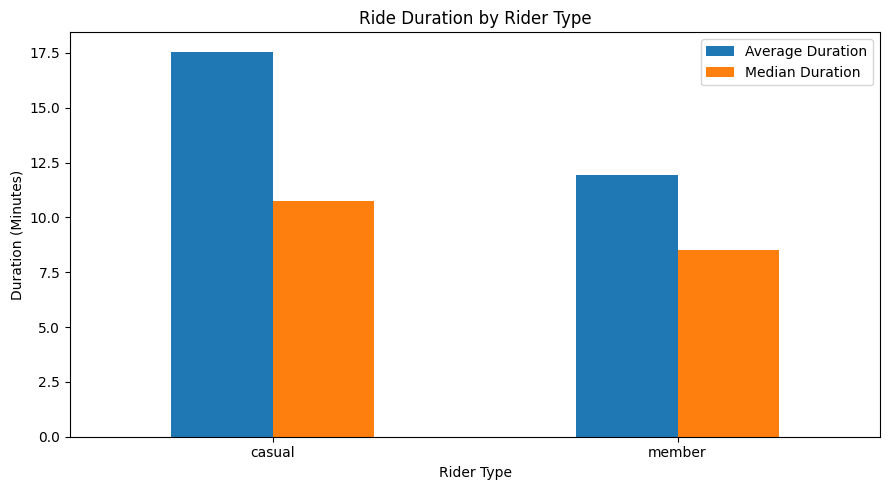

In [37]:
import matplotlib.pyplot as plt

duration_comparison.set_index('member_casual')[
    ['avg_duration_minutes', 'median_duration_minutes']
].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Ride Duration by Rider Type')
plt.xlabel('Rider Type')
plt.ylabel('Duration (Minutes)')
plt.xticks(rotation=0)
plt.legend(['Average Duration', 'Median Duration'])
plt.tight_layout()
plt.show()

In [38]:
weekday_trends = con.execute("""
    SELECT
        strftime(started_at, '%A') AS day_of_week,
        EXTRACT(ISODOW FROM started_at) AS day_number,
        member_casual,
        COUNT(*) AS total_rides
    FROM analysis_trips
    WHERE started_at >= TIMESTAMP '2025-10-01'
      AND started_at < TIMESTAMP '2026-10-01'
    GROUP BY
        day_of_week,
        day_number,
        member_casual
    ORDER BY
        day_number,
        member_casual
""").df()

weekday_trends

,day_of_week,day_number,member_casual,total_rides
0,Monday,1,casual,251216
1,Monday,1,member,555584
2,Tuesday,2,casual,249288
3,Tuesday,2,member,641038
4,Wednesday,3,casual,254830
5,Wednesday,3,member,644595
6,Thursday,4,casual,271742
7,Thursday,4,member,628501
8,Friday,5,casual,342710
9,Friday,5,member,585199


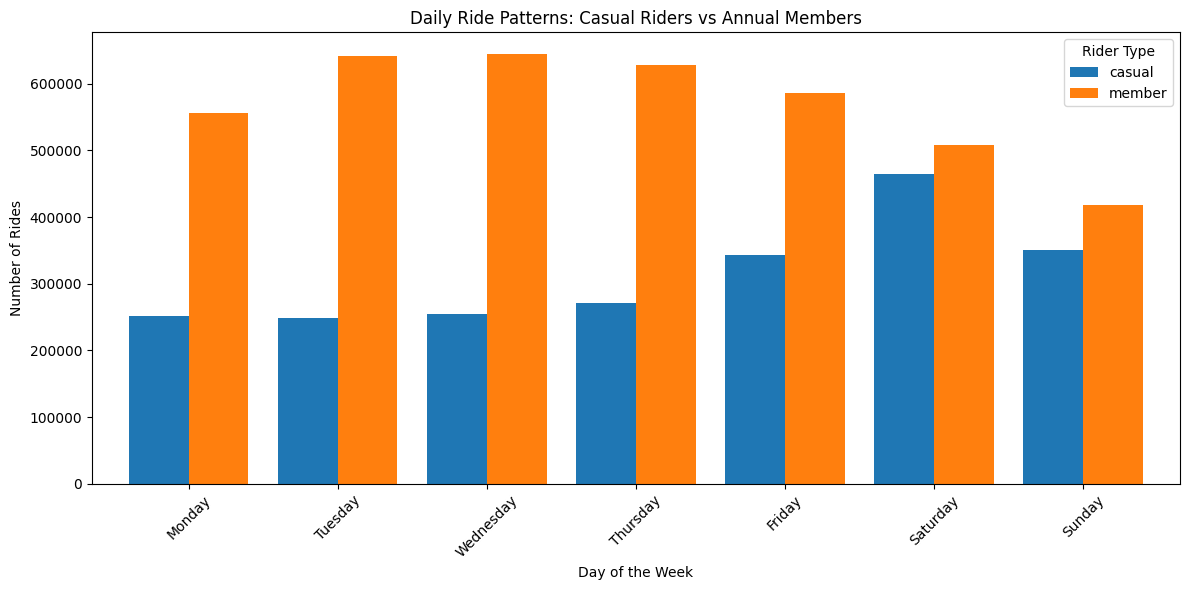

In [39]:
import matplotlib.pyplot as plt

weekday_pivot = weekday_trends.pivot(
    index='day_number',
    columns='member_casual',
    values='total_rides'
)

weekday_pivot.index = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_pivot.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Daily Ride Patterns: Casual Riders vs Annual Members')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Rides')
plt.xticks(rotation=45)
plt.legend(title='Rider Type')
plt.tight_layout()
plt.show()

In [40]:
import os

visualization_path = "/content/drive/MyDrive/Cyclistic_Project/visualizations"

os.makedirs(visualization_path, exist_ok=True)

print("Visualization folder created successfully!")

Visualization folder created successfully!


In [41]:
import matplotlib.pyplot as plt

# 1. Monthly ride trends
ax = monthly_pivot.plot(
    kind='line', figsize=(12, 6), marker='o'
)
ax.set_title('Monthly Ride Trends: Casual vs Members')
ax.set_xlabel('Month')
ax.set_ylabel('Number of Rides')
ax.tick_params(axis='x', rotation=45)
ax.figure.tight_layout()
ax.figure.savefig(
    visualization_path + "/monthly_ride_trends.png",
    dpi=300, bbox_inches='tight'
)
plt.close(ax.figure)


# 2. Ride duration comparison
ax = duration_comparison.set_index('member_casual')[
    ['avg_duration_minutes', 'median_duration_minutes']
].plot(kind='bar', figsize=(9, 5))

ax.set_title('Ride Duration by Rider Type')
ax.set_xlabel('Rider Type')
ax.set_ylabel('Duration (Minutes)')
ax.tick_params(axis='x', rotation=0)
ax.figure.tight_layout()
ax.figure.savefig(
    visualization_path + "/ride_duration_comparison.png",
    dpi=300, bbox_inches='tight'
)
plt.close(ax.figure)


# 3. Weekday ride patterns
ax = weekday_pivot.plot(
    kind='bar', figsize=(12, 6), width=0.8
)
ax.set_title('Daily Ride Patterns: Casual vs Members')
ax.set_xlabel('Day of the Week')
ax.set_ylabel('Number of Rides')
ax.tick_params(axis='x', rotation=45)
ax.figure.tight_layout()
ax.figure.savefig(
    visualization_path + "/weekday_ride_patterns.png",
    dpi=300, bbox_inches='tight'
)
plt.close(ax.figure)

print("All three charts saved successfully!")

All three charts saved successfully!


In [42]:
documentation_path = "/content/drive/MyDrive/Cyclistic_Project/docs"

os.makedirs(documentation_path, exist_ok=True)

print("Documentation folder created successfully!")

Documentation folder created successfully!


In [43]:
cleaning_notes = """
# Cyclistic Data Cleaning Documentation

## 1. Dataset Overview
- Study period: October 2025 to September 2026.
- Source: Divvy trip data.
- Number of monthly CSV files: 12.
- Original combined records: 6,171,785.

## 2. Data Preparation

### Duplicate Records
- Identified 35 duplicate ride records.
- All duplicate groups contained identical records.
- Removed duplicates using ride_id.
- Records after deduplication: 6,171,750.

### Missing Values
Missing values were identified in:
- start_station_name: 1,289,480
- end_station_name: 1,355,473
- end_lat: 5,445
- end_lng: 5,445

These records were retained because missing station information
does not prevent the main rider-type and ride-duration analyses.

### Ride Duration Filtering
Excluded records that did not meet these conditions:
- ended_at must be later than started_at.
- Ride duration must not exceed 24 hours.

Records after filtering: 6,166,404.

A total of 5,346 records were excluded by this filtering step.

## 3. Data Anomaly
The CSV supplied in the January 2026 download was named
202501-divvy-tripdata.csv, although its timestamps showed
January 2026 data. The file was renamed to
202601-divvy-tripdata.csv for consistency.

## 4. Final Analysis Dataset
The final analysis table was named analysis_trips.

Final records: 6,166,404.

The original all_trips table was preserved.
"""

with open(documentation_path + "/data_cleaning.md", "w") as file:
    file.write(cleaning_notes)

print("Data cleaning documentation saved successfully!")

Data cleaning documentation saved successfully!


In [44]:
readme_content = """
# Cyclistic Bike-Share Analysis

## Project Overview

This project analyses Cyclistic bike-share usage to understand
how annual members and casual riders use the service differently.

The goal is to identify usage patterns and recommend strategies
to convert more casual riders into annual members.

## Business Question

How do annual members and casual riders use Cyclistic bikes differently,
and how can Cyclistic convert more casual riders into annual members?

## Study Period

October 2025 – September 2026

## Tools Used

- Python
- SQL (DuckDB)
- Google Colab
- Pandas
- Matplotlib

## Data Preparation

- Combined 12 monthly CSV files.
- Removed 35 duplicate records.
- Reviewed missing values and retained records with incomplete
  station information.
- Excluded records with invalid ride durations or durations
  exceeding 24 hours.
- Final analysis dataset: 6,166,404 rides.

See `docs/data_cleaning.md` for details.

## Key Findings

### 1. Monthly Ride Trends

Annual members recorded more rides than casual riders in every
month of the study period. Both groups showed increased activity
during warmer months.

![Monthly Ride Trends](visualizations/monthly_ride_trends.png)

### 2. Ride Duration

Casual riders had longer rides than annual members.

- Casual riders: 17.56 minutes average duration.
- Annual members: 11.92 minutes average duration.

![Ride Duration Comparison](visualizations/ride_duration_comparison.png)

### 3. Day-of-Week Patterns

Casual riders showed stronger weekend usage, particularly on
Saturdays. Annual members recorded stronger weekday usage.

![Weekday Ride Patterns](visualizations/weekday_ride_patterns.png)

## Business Recommendations

1. Introduce weekend-focused membership promotions.
2. Promote annual membership benefits to frequent casual riders.
3. Launch seasonal membership campaigns during periods of
   increased riding activity.

These recommendations should be tested and evaluated to measure
their impact on membership conversions.

## Conclusion

The analysis indicates that casual riders tend to take longer
rides and are more active on weekends, while annual members
generate more rides overall and show stronger weekday usage.

Cyclistic can use these differences to develop targeted
marketing strategies aimed at converting casual riders into
annual members.

## Repository Structure

- `Cyclistic_Bike_Share_Analysis.ipynb` – Analysis notebook
- `Cyclistic_Data/` – Source data (not included in the public repository)
- `visualizations/` – Analysis charts
- `docs/` – Project documentation

## Data Source

Divvy trip data:
https://divvybikes-marketing.lyft.net/system-data

Raw source data is not included in this repository.

## AI Assistance and Acknowledgement

ChatGPT (OpenAI) was used as a learning and guidance assistant
throughout this project.

It provided step-by-step guidance on:
- Data preparation and cleaning.
- SQL queries using DuckDB.
- Python analysis and data visualisation.
- Understanding analytical findings.
- Developing business insights and recommendations.
- Organising and documenting the project.

The analysis, review and project decisions were completed
as part of my learning process, with AI assistance.

"""

readme_path = "/content/drive/MyDrive/Cyclistic_Project/README.md"

with open(readme_path, "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [45]:
import os

project_path = "/content/drive/MyDrive/Cyclistic_Project"

for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d != "Cyclistic_Data"]

    level = root.replace(project_path, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Cyclistic_Project/
    Cyclistic_Bike_Share_Analysis.ipynb
    cyclistic.duckdb
    README.md
    visualizations/
        monthly_ride_trends.png
        ride_duration_comparison.png
        weekday_ride_patterns.png
    docs/
        data_cleaning.md


In [46]:
gitignore_content = """
# Raw dataset
Cyclistic_Data/

# DuckDB database
*.duckdb
*.wal

# Python temporary files
__pycache__/
*.pyc

# Colab checkpoints
.ipynb_checkpoints/
"""

with open(project_path + "/.gitignore", "w") as file:
    file.write(gitignore_content)

print(".gitignore created successfully!")

.gitignore created successfully!
